In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Settingan agar DataFrame interaktif dan lebar
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Library berhasil di-import!")

Library berhasil di-import!


In [2]:
# Menerima dan membaca file .xls
df_read = pd.read_html('dataset.xls')
df_raw = df_read[0]

# Ambil hanya pada variabel tertentu
print(f"Total data mentah: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom.")
display(df_raw.head(5))

Total data mentah: 260 baris, 16 kolom.


,periode_data,triwulan,bulan,wilayah,kecamatan,kelurahan,jumlah_rata_rata_ketinggian_air,jumlah_rw_terdampak,jumlah_kk_terdampak,jumlah_jiwa_terdampak,jumlah_kejadian,jumlah_korban_meninggal,jumlah_korban_luka,jumlah_pengungsi,jumlah_tempat_pengungsian,nilai_kerugian
0,202406,2,6,KOTA ADM. JAKARTA UTARA,PENJARINGAN,PLUIT,10 S.D 60 CM,1,0,0,12,0,0,0,0,0
1,202403,1,1,KOTA ADM. JAKARTA BARAT,CENGKARENG,CENGKARENG TIMUR,30 S.D 40 CM,2,0,0,2,0,0,0,0,0
2,202403,1,1,KOTA ADM. JAKARTA BARAT,KEMBANGAN,JOGLO,30 S.D 40 CM,1,0,0,1,0,0,0,0,0
3,202403,1,1,KOTA ADM. JAKARTA BARAT,KALI DERES,KAMAL,30 CM,1,0,0,1,0,0,0,0,0
4,202403,1,1,KOTA ADM. JAKARTA BARAT,CENGKARENG,KAPUK,30 CM,1,0,0,1,0,0,0,0,0


In [3]:
# Memilih 5 kolom spesifik
kolom_pilihan = ['bulan', 'wilayah', 'kecamatan', 'kelurahan', 'jumlah_rata_rata_ketinggian_air']
df_filtered = df_raw[kolom_pilihan].copy()

# Sorting berdasarkan bulan (1 hingga 12)
df_filtered = df_filtered.sort_values(by='bulan', ascending=True).reset_index(drop=True)

print("Data Setelah Filtering & Sorting Bulan:")
display(df_filtered.head(10))

Data Setelah Filtering & Sorting Bulan:


,bulan,wilayah,kecamatan,kelurahan,jumlah_rata_rata_ketinggian_air
0,1,KOTA ADM. JAKARTA BARAT,CENGKARENG,CENGKARENG TIMUR,30 S.D 40 CM
1,1,KOTA ADM. JAKARTA BARAT,KEMBANGAN,JOGLO,30 S.D 40 CM
2,1,KOTA ADM. JAKARTA BARAT,KALI DERES,KAMAL,30 CM
3,1,KOTA ADM. JAKARTA SELATAN,KEBAYORAN LAMA,CIPULIR,30 S.D 100 CM
4,1,KOTA ADM. JAKARTA SELATAN,CILANDAK,GANDARIA SELATAN,30 CM
5,1,KOTA ADM. JAKARTA SELATAN,PANCORAN,DUREN TIGA,30 S.D 50 CM
6,1,KOTA ADM. JAKARTA SELATAN,PASAR MINGGU,JATI PADANG,10 S.D 40 CM
7,1,KOTA ADM. JAKARTA SELATAN,PANCORAN,KALIBATA,40 S.D 60 CM
8,1,KOTA ADM. JAKARTA SELATAN,CILANDAK,LEBAK BULUS,30 S.D 60 CM
9,1,KOTA ADM. JAKARTA SELATAN,KEBAYORAN LAMA,KEBAYORAN LAMA UTARA,30 CM


In [4]:
import re

def ekstraksi_ketinggian_air(val):
    if pd.isna(val):
        return np.nan

    # Hapus semua kata 'CM' agar menyisahkan nilai eksak
    val_str = str(val).upper().replace('CM', '').strip()

    # Jika berupa rentang (contoh: "10 S.D 60") -> Ambil Nilai Tengah (Midpoint)
    if 'S.D' in val_str:
        angka = re.findall(r'\d+', val_str)
        if len(angka) >= 2:
            min_val = float(angka[0])
            max_val = float(angka[1])
            return (min_val + max_val) / 2 # Rata-rata nilai tengah rentang

    # Jika angka fix (contoh: "30")
    try:
        return float(val_str)
    except:
        return np.nan

# Fungsi ekstraksi nilai tengah
df_filtered['ketinggian_air_final'] = df_filtered['jumlah_rata_rata_ketinggian_air'].apply(ekstraksi_ketinggian_air)

print("Pembersihan Berhasil! Data Ketinggian Air Sekarang Bervariasi Secara Alami:")
display(df_filtered[['bulan', 'kecamatan', 'kelurahan', 'jumlah_rata_rata_ketinggian_air', 'ketinggian_air_final']].head(15))

Pembersihan Berhasil! Data Ketinggian Air Sekarang Bervariasi Secara Alami:


,bulan,kecamatan,kelurahan,jumlah_rata_rata_ketinggian_air,ketinggian_air_final
0,1,CENGKARENG,CENGKARENG TIMUR,30 S.D 40 CM,35.0
1,1,KEMBANGAN,JOGLO,30 S.D 40 CM,35.0
2,1,KALI DERES,KAMAL,30 CM,30.0
3,1,KEBAYORAN LAMA,CIPULIR,30 S.D 100 CM,65.0
4,1,CILANDAK,GANDARIA SELATAN,30 CM,30.0
5,1,PANCORAN,DUREN TIGA,30 S.D 50 CM,40.0
6,1,PASAR MINGGU,JATI PADANG,10 S.D 40 CM,25.0
7,1,PANCORAN,KALIBATA,40 S.D 60 CM,50.0
8,1,CILANDAK,LEBAK BULUS,30 S.D 60 CM,45.0
9,1,KEBAYORAN LAMA,KEBAYORAN LAMA UTARA,30 CM,30.0


In [5]:
#202531082_Todo Christanto Pangamudi Simanjuntak
# 1. Menyiapkan Fitur (Bulan + Identitas Kelurahan)
X = pd.get_dummies(df_filtered[['bulan', 'kelurahan']], columns=['kelurahan'], drop_first=True)
y = df_filtered['ketinggian_air_final']

# 2. Fit Model Regresi Linier
model_reg = LinearRegression()
model_reg.fit(X, y)

# 3. Prediksi Ketinggian Air Spesifik per Kelurahan
df_filtered['prediksi_ketinggian_cm'] = model_reg.predict(X)

print("=== HASIL PREDIKSI BERVARIASI PER KELURAHAN ===")
display(df_filtered[['bulan', 'wilayah', 'kecamatan', 'kelurahan', 'ketinggian_air_final', 'prediksi_ketinggian_cm']].head(15))

=== HASIL PREDIKSI BERVARIASI PER KELURAHAN ===


,bulan,wilayah,kecamatan,kelurahan,ketinggian_air_final,prediksi_ketinggian_cm
0,1,KOTA ADM. JAKARTA BARAT,CENGKARENG,CENGKARENG TIMUR,35.0,37.381584
1,1,KOTA ADM. JAKARTA BARAT,KEMBANGAN,JOGLO,35.0,46.074585
2,1,KOTA ADM. JAKARTA BARAT,KALI DERES,KAMAL,30.0,31.131584
3,1,KOTA ADM. JAKARTA SELATAN,KEBAYORAN LAMA,CIPULIR,65.0,45.210543
4,1,KOTA ADM. JAKARTA SELATAN,CILANDAK,GANDARIA SELATAN,30.0,32.859668
5,1,KOTA ADM. JAKARTA SELATAN,PANCORAN,DUREN TIGA,40.0,33.157919
6,1,KOTA ADM. JAKARTA SELATAN,PASAR MINGGU,JATI PADANG,25.0,35.447376
7,1,KOTA ADM. JAKARTA SELATAN,PANCORAN,KALIBATA,50.0,43.394751
8,1,KOTA ADM. JAKARTA SELATAN,CILANDAK,LEBAK BULUS,45.0,35.736863
9,1,KOTA ADM. JAKARTA SELATAN,KEBAYORAN LAMA,KEBAYORAN LAMA UTARA,30.0,30.000000


/tmp/ipykernel_9004/3598023554.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top10, x='prediksi_ketinggian_cm', y='kelurahan', ax=axes[1], palette='Reds_r')


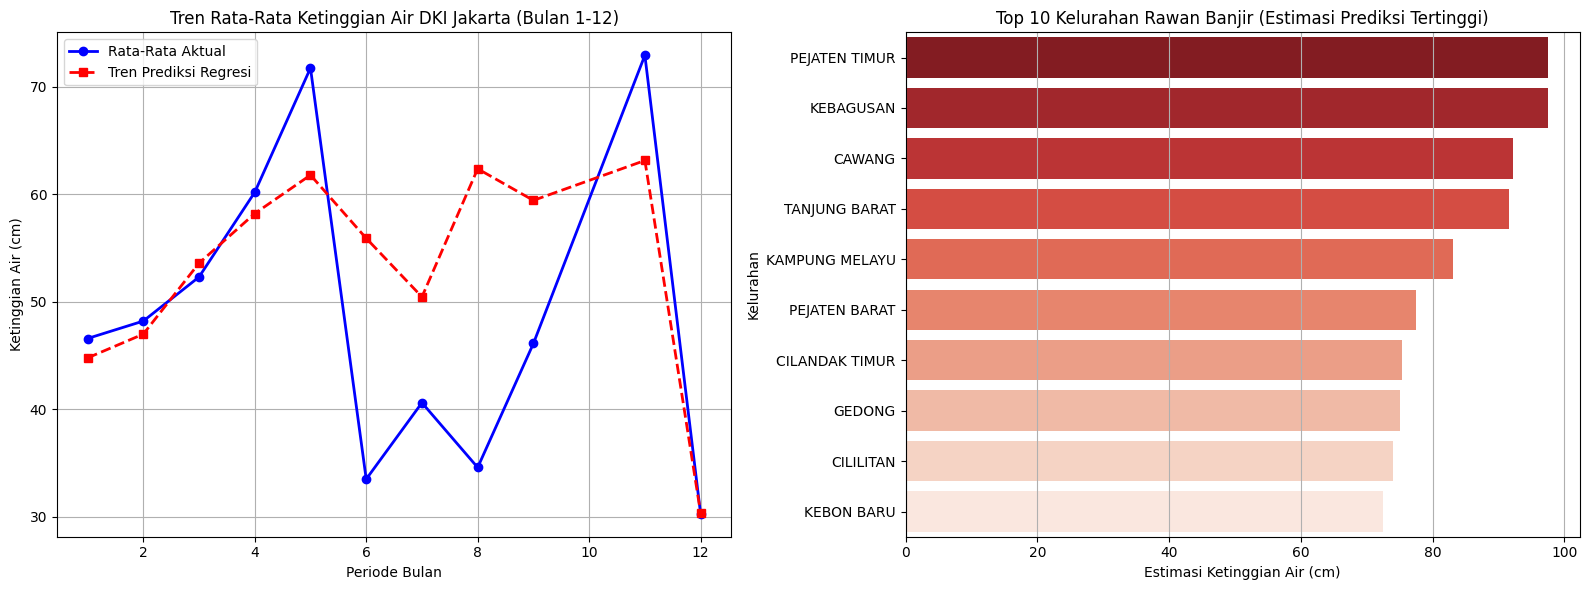

In [6]:
# Membuat kanvas 2 grafik berdampingan (1 baris, 2 kolom)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# GRAFIK 1: Tren Rata-Rata Aktual vs Prediksi Regresi per Bulan
df_monthly = df_filtered.groupby('bulan')[['ketinggian_air_final', 'prediksi_ketinggian_cm']].mean().reset_index()

axes[0].plot(df_monthly['bulan'], df_monthly['ketinggian_air_final'], marker='o', color='blue', linewidth=2, label='Rata-Rata Aktual')
axes[0].plot(df_monthly['bulan'], df_monthly['prediksi_ketinggian_cm'], marker='s', color='red', linestyle='--', linewidth=2, label='Tren Prediksi Regresi')
axes[0].set_title('Tren Rata-Rata Ketinggian Air DKI Jakarta (Bulan 1-12)')
axes[0].set_xlabel('Periode Bulan')
axes[0].set_ylabel('Ketinggian Air (cm)')
axes[0].grid(True)
axes[0].legend()

# GRAFIK 2: Top 10 Kelurahan dengan Prediksi Ketinggian Air Tertinggi
df_top10 = df_filtered.groupby('kelurahan')['prediksi_ketinggian_cm'].mean().nlargest(10).reset_index()

sns.barplot(data=df_top10, x='prediksi_ketinggian_cm', y='kelurahan', ax=axes[1], palette='Reds_r')
axes[1].set_title('Top 10 Kelurahan Rawan Banjir (Estimasi Prediksi Tertinggi)')
axes[1].set_xlabel('Estimasi Ketinggian Air (cm)')
axes[1].set_ylabel('Kelurahan')
axes[1].grid(True, axis='x')

plt.tight_layout()
plt.show()